# Vor-Notebook: Methodenwahl TF-IDF

**Zweck:** Dieses Notebook begründet die Konfiguration des TF-IDF-Scorings, bevor das Skript gebaut wird. Es prüft, ob die Einstellungen sinnvoll sind, und zeigt, wie empfindlich die Kennzahlen auf Alternativen reagieren.

**Regel:** Die Hauptkonfiguration steht vorab fest (Baseline-Konfiguration). Dieses Notebook wählt sie **nicht** nach dem Ergebnis aus. Es enthält bewusst keine Signifikanztests, nur Kennzahlen und Prüfungen. Die Tests folgen später im Auswertungs-Notebook.

| Abschnitt | Inhalt |
|---|---|
| 1 | Festgelegte Konfiguration und Alternativen |
| 2 | Daten laden |
| 3 | Mini-Beispiel: Wie ein Score entsteht und warum eine Zeile ihn verändert |
| 4 | Plausibilitätsprüfungen |
| 5 | Abdeckung des Vokabulars: Welche Wörter der Zwillinge wirken überhaupt? |
| 6 | Stoppwörter bei Bewertungswörtern |
| 7 | Beispiel an einem echten Zwilling |
| 8 | Sensitivität: Kennzahlen je Konfiguration |

In [13]:
from collections import Counter
from datetime import date
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer

try:
    from IPython.display import display
except ImportError:
    display = print

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)


def finde_repo():
    # Hauptordner des Repos: der erste Ordner (von hier nach oben), der data/processed enthält
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "data" / "processed").exists():
            return q
    raise SystemExit("Repo-Hauptordner nicht gefunden. Das Notebook im Repo starten.")


ROOT = finde_repo()
MARKT = ROOT / "data/processed/jobmarket_data-engineer_180cv_2026-10-20.parquet"
CV_ROH = ROOT / "data/raw/djinni/cv_profiles_en.parquet"
JOB_ROH = ROOT / "data/raw/djinni/job_postings_en.parquet"
ZW_SCHLANK = ROOT / "data/processed/twins_vollauf_v2.parquet"
ZW_VOLL = ROOT / "twins/vollauf/vollauf_zwillinge.parquet"
AUS = ROOT / "twins/vollauf/auswertung"
AUS.mkdir(parents=True, exist_ok=True)
print("Repo:", ROOT, "| scikit-learn", sklearn.__version__)

Repo: C:\Users\ayla-\Dokumente\Projekt2\project_nobias | scikit-learn 1.9.1


## 1. Festgelegte Konfiguration und Alternativen

**Hauptkonfiguration = Baseline** (Stoppwörter `english`, eigenes Token-Muster, sonst Standardwerte, angepasst auf Stellen und Bewerberliste). So bleibt der Vergleich mit MeritMe auf derselben Referenz.

Die Alternativen dienen nur der Sensitivitätsanalyse (Abschnitt 8). Sie wurden **vor** dem Blick auf Ergebnisse festgelegt:

| Name | Änderung gegenüber der Baseline |
|---|---|
| `baseline` | keine |
| `sublinear_tf` | häufige Wörter werden gedämpft (`sublinear_tf=True`) |
| `ngram_1_2` | auch Wortpaare zählen (`ngram_range=(1, 2)`) |
| `ohne_stoppwoerter` | keine Stoppwortliste |
| `fit_nur_jobs` | Gewichte nur aus den Stellen berechnet |
| `fit_mit_originalen` | Gewichte aus Stellen, Bewerberliste und Original-CVs berechnet (Zwillinge nie) |

In [14]:
TOKEN_PATTERN = r"(?u)(?<![\w.])\.?\w(?:[\w.]*\w)?[+#]*"
BASIS = dict(stop_words="english", token_pattern=TOKEN_PATTERN)

KONFIGS = {
    "baseline": dict(vec=dict(BASIS), fit="jobs+liste"),
    "sublinear_tf": dict(vec=dict(BASIS, sublinear_tf=True), fit="jobs+liste"),
    "ngram_1_2": dict(vec=dict(BASIS, ngram_range=(1, 2)), fit="jobs+liste"),
    "ohne_stoppwoerter": dict(vec=dict(token_pattern=TOKEN_PATTERN), fit="jobs+liste"),
    "fit_nur_jobs": dict(vec=dict(BASIS), fit="jobs"),
    "fit_mit_originalen": dict(vec=dict(BASIS), fit="jobs+liste+originale"),
}
HAUPT = "baseline"

ORDNUNG = ["edu", "lin", "tone", "para", "all"]
POOL_NUR_RING = False   # True: Rang nur innerhalb des Rings

## 2. Daten laden
Wie im Auswertungs-Notebook: Stellen und Bewerberliste aus der Marktdatei, Zwillinge aus der lokalen Tabelle (mit Originaltexten) oder aus der Datei fürs Team (Originaltexte werden dann aus den Djinni-Rohdaten ergänzt).

In [15]:
markt = pd.read_parquet(MARKT)
cv = pd.read_parquet(CV_ROH)
cv = cv[cv["id"].isin(markt["id"])].drop_duplicates("id").copy()
jobs = pd.read_parquet(JOB_ROH)
jobs = jobs[jobs["id"].isin(markt["id"])].drop_duplicates("id").copy()


def verketten(df, spalten):
    text = df[spalten[0]].fillna("").astype(str)
    for s in spalten[1:]:
        text = text + "\n" + df[s].fillna("").astype(str)
    return text.str.strip()


cv["text"] = verketten(cv, ["Position", "Highlights", "Moreinfo"])
jobs["text"] = verketten(jobs, ["Position", "Long Description"])

job_docs = markt[markt["role"] == "job"].merge(jobs[["id", "text"]], on="id", how="left").reset_index(drop=True)
liste = markt[markt["role"] == "liste"].merge(cv[["id", "text"]], on="id", how="left").reset_index(drop=True)
assert job_docs["text"].notna().all() and liste["text"].notna().all(), "Texte fehlen, Rohdaten prüfen"

if ZW_VOLL.exists():
    zw = pd.read_parquet(ZW_VOLL)
elif ZW_SCHLANK.exists():
    zw = pd.read_parquet(ZW_SCHLANK)
else:
    raise SystemExit("Keine Zwillingstabelle gefunden.")
if "verwendbar" in zw.columns:
    zw = zw[zw["verwendbar"]]
zw = zw.reset_index(drop=True).copy()
if "text_original" not in zw.columns:
    zw["text_original"] = zw["id"].map(cv.set_index("id")["text"])
    assert zw["text_original"].notna().all(), "Originaltexte nicht gefunden (Spalte id)"
    print("Hinweis: Originaltexte aus den Djinni-Rohdaten rekonstruiert.")
zw["richtung"] = zw["richtung"].fillna("").astype(str).replace({"None": "", "nan": ""})

jidx_map = {jid: k for k, jid in enumerate(job_docs["id"])}
jidx = zw["assigned_job_id"].map(jidx_map).to_numpy()
assert not np.isnan(jidx.astype(float)).any(), "Zugeordnete Jobs fehlen im Markt"
jidx = jidx.astype(int)

if POOL_NUR_RING:
    maske = job_docs["ring"].to_numpy()[:, None] == liste["ring"].to_numpy()[None, :]
else:
    maske = np.ones((len(job_docs), len(liste)), dtype=bool)

print(f"{len(job_docs)} Stellen, {len(liste)} Listen-CVs, {len(zw)} Zwillinge, {zw['cv_id'].nunique()} Quell-CVs")

20 Stellen, 60 Listen-CVs, 600 Zwillinge, 120 Quell-CVs


## 3. Mini-Beispiel: Wie ein Score entsteht
Die Stelle verlangt `python` und `sql`. CV A hat genau diese beiden Wörter. CV B hat dieselben Wörter plus eine Bildungszeile.

- **Fall 1:** Die Wörter der Zeile sind dem Vektorisierer bekannt (sie kommen in den Anpassungstexten vor). Dann verdünnen sie die Skills, der Score sinkt.
- **Fall 2:** Die Wörter der Zeile sind unbekannt. Dann werden sie ignoriert, der Score bleibt gleich.

(Zur Veranschaulichung ohne IDF-Gewichtung gerechnet, damit die Zahlen nachvollziehbar bleiben.)

In [16]:
stelle = "python sql"
cv_a = "python sql"
cv_b = "python sql bachelor degree computer science"

fall1 = TfidfVectorizer(use_idf=False).fit([stelle, cv_a, cv_b])           # Zeilenwörter bekannt
fall2 = TfidfVectorizer(use_idf=False).fit([stelle, cv_a])                 # Zeilenwörter unbekannt


def cosinus(v, a, b):
    return float((v.transform([a]).multiply(v.transform([b])).sum()))


zeilen = [
    {"Fall": "1: Zeilenwörter bekannt", "Score CV A": cosinus(fall1, stelle, cv_a), "Score CV B": cosinus(fall1, stelle, cv_b)},
    {"Fall": "2: Zeilenwörter unbekannt", "Score CV A": cosinus(fall2, stelle, cv_a), "Score CV B": cosinus(fall2, stelle, cv_b)},
]
display(pd.DataFrame(zeilen).round(3))

,Fall,Score CV A,Score CV B
0,1: Zeilenwörter bekannt,1.0,0.577
1,2: Zeilenwörter unbekannt,1.0,1.000


## 4. Plausibilitätsprüfungen
Grundprüfungen für die Baseline-Konfiguration:
1. Jeder Text hat zu sich selbst den Score 1 (Vektorlänge 1).
2. Es gibt keine Texte, deren Vektor leer ist (kein bekanntes Wort). Sie hätten den Score 0 zu jeder Stelle.
3. Die Scores liegen zwischen 0 und 1.

In [17]:
def anpassen(name):
    k = KONFIGS[name]
    texte = list(job_docs["text"])
    if "liste" in k["fit"]:
        texte += list(liste["text"])
    if "originale" in k["fit"]:
        texte += list(zw["text_original"].drop_duplicates())
    return TfidfVectorizer(**k["vec"]).fit(texte)


def rechne(name):
    v = anpassen(name)
    J = v.transform(job_docs["text"])
    L = v.transform(liste["text"])
    O = v.transform(zw["text_original"])
    T = v.transform(zw["text_zwilling"])
    JL = (J @ L.T).toarray()
    s_o = np.asarray(O.multiply(J[jidx]).sum(axis=1)).ravel()
    s_t = np.asarray(T.multiply(J[jidx]).sum(axis=1)).ravel()
    return v, J, L, O, T, JL, s_o, s_t


vec, J, L, O, T, JL, s_o, s_t = rechne(HAUPT)

selbst = np.asarray(L.multiply(L).sum(axis=1)).ravel()
leer_liste = int((selbst == 0).sum())
leer_orig = int((np.asarray(O.sum(axis=1)).ravel() == 0).sum())
leer_zw = int((np.asarray(T.sum(axis=1)).ravel() == 0).sum())
pruefung = pd.DataFrame([
    {"Prüfung": "Selbst-Score der Listen-CVs ist 1 (ohne leere Texte)", "Ergebnis": f"min {selbst[selbst > 0].min():.4f}, max {selbst.max():.4f}"},
    {"Prüfung": "Leere Vektoren: Listen-CVs / Originale / Zwillinge", "Ergebnis": f"{leer_liste} / {leer_orig} / {leer_zw}"},
    {"Prüfung": "Score-Bereich Stelle gegen Listen-CVs", "Ergebnis": f"{JL.min():.3f} bis {JL.max():.3f}"},
    {"Prüfung": "Score Original / Zwilling (zugeordnete Stelle), Median", "Ergebnis": f"{np.median(s_o):.3f} / {np.median(s_t):.3f}"},
])
display(pruefung)

,Prüfung,Ergebnis
0,Selbst-Score der Listen-CVs ist 1 (ohne leere Texte),"min 1.0000, max 1.0000"
1,Leere Vektoren: Listen-CVs / Originale / Zwillinge,0 / 0 / 0
2,Score-Bereich Stelle gegen Listen-CVs,0.002 bis 0.358
3,"Score Original / Zwilling (zugeordnete Stelle), Median",0.105 / 0.105


## 5. Abdeckung des Vokabulars
Der Vektorisierer kennt nur Wörter, die in den Anpassungstexten vorkommen. Wörter eines Zwillings, die er nicht kennt, werden ignoriert. Hier wird gezählt, was jeder Zwilling gegenüber dem Original **neu hinzufügt** und **entfernt** (nach Stoppwort-Entfernung) und wie viel davon dem Vektorisierer bekannt ist. Nur bekannte Wörter können den Score verändern.

In [18]:
analyse = vec.build_analyzer()
vokabular = set(vec.vocabulary_)

zeilen = []
neu_je_variante = {v: Counter() for v in ORDNUNG}
weg_je_variante = {v: Counter() for v in ORDNUNG}
for _, r in zw.iterrows():
    a = Counter(analyse(r["text_original"]))
    b = Counter(analyse(r["text_zwilling"]))
    neu = b - a
    weg = a - b
    n_neu = sum(neu.values())
    n_neu_bek = sum(c for w, c in neu.items() if w in vokabular)
    n_weg = sum(weg.values())
    n_weg_bek = sum(c for w, c in weg.items() if w in vokabular)
    zeilen.append({"variante": r["variante"], "n_orig": sum(a.values()), "neu": n_neu, "neu_bekannt": n_neu_bek,
                   "weg": n_weg, "weg_bekannt": n_weg_bek})
    if r["variante"] in neu_je_variante:
        neu_je_variante[r["variante"]].update(neu)
        weg_je_variante[r["variante"]].update(weg)

ab = pd.DataFrame(zeilen)
ueberblick = ab.groupby("variante").agg(n=("neu", "size"), median_woerter_orig=("n_orig", "median"),
                                        median_neu=("neu", "median"), median_neu_bekannt=("neu_bekannt", "median"),
                                        median_weg=("weg", "median"), median_weg_bekannt=("weg_bekannt", "median")).reindex(ORDNUNG)
ueberblick["anteil_neu_bekannt"] = (ab.groupby("variante")["neu_bekannt"].sum() / ab.groupby("variante")["neu"].sum().replace(0, np.nan)).reindex(ORDNUNG)
display(ueberblick.round(3))

,n,median_woerter_orig,median_neu,median_neu_bekannt,median_weg,median_weg_bekannt,anteil_neu_bekannt
variante,,,,,,,
edu,120,101.0,6.0,6.0,0.0,0.0,0.948
lin,120,101.0,3.5,3.5,0.0,0.0,1.000
tone,120,101.0,3.0,2.0,1.0,0.0,0.665
para,120,101.0,8.0,6.0,8.5,7.0,0.695
all,120,101.0,14.0,12.0,0.0,0.0,0.864


In [19]:
# Die häufigsten neuen und entfernten Wörter je Variante (K = dem Vektorisierer bekannt)
for v in ORDNUNG:
    neu = [f"{w}{'' if w in vokabular else ' (unbekannt)'} {c}" for w, c in neu_je_variante[v].most_common(10)]
    weg = [f"{w}{'' if w in vokabular else ' (unbekannt)'} {c}" for w, c in weg_je_variante[v].most_common(10)]
    print(f"--- {v} ---")
    print("neu :", "; ".join(neu) or "-")
    print("weg :", "; ".join(weg) or "-")

--- edu ---
neu : bachelor 41; completed 40; professional 40; certification 40; courses 40; software 40; development 40; s 40; degree 40; computer 40
weg : university 6; degree 5; s 5; bachelor 4; master 4; kyiv 3; applied 3; education 2; national 2; student (unbekannt) 2
--- lin ---
neu : previously 60; worked 60; customer 60; support 60; moving 60; continuous 60; career 60
weg : -
--- tone ---
neu : successfully 81; fairly (unbekannt) 47; strong 46; proven 37; successful 13; actively (unbekannt) 8; help 7; hoping (unbekannt) 7; reasonably (unbekannt) 7; good 7
weg : working 7; looking 6; experienced 4; experience 4; good 4; expertise 3; proficient 3; using 3; enhancing 3; solid 3
--- para ---
neu : building 62; built 53; took 18; worked 17; build 16; various 14; writing 14; used 14; carried (unbekannt) 13; working 12
weg : using 64; creating 33; developing 31; developed 29; created 27; development 23; different 18; working 18; experience 17; develop 15
--- all ---
neu : worked 120; c

## 6. Stoppwörter bei Bewertungswörtern
`tone` ändert Bewertungswörter. Steht ein solches Wort auf der Stoppwortliste, verschwindet es und hat keine Wirkung. Die Liste unten zeigt typische Wörter und ob sie in der Stoppwortliste stehen.

In [20]:
woerter = ["very", "many", "several", "often", "mostly", "also", "fairly", "quite", "really", "think", "somewhat",
           "huge", "extensive", "strong", "good", "excellent", "expert", "highly", "confident", "believe"]
display(pd.DataFrame({"wort": woerter, "auf_stoppwortliste": [w in ENGLISH_STOP_WORDS for w in woerter],
                      "im_vokabular": [w in vokabular for w in woerter]}).set_index("wort").T)

wort,very,many,several,often,mostly,also,fairly,quite,really,think,somewhat,huge,extensive,strong,good,excellent,expert,highly,confident,believe
auf_stoppwortliste,True,True,True,True,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False
im_vokabular,False,False,False,False,False,False,False,True,True,False,False,True,True,True,True,True,True,True,True,False


## 7. Beispiel an einem echten Zwilling
Zeigt, welche Wörter gegenüber dem Original hinzukommen, ihr Gewicht (IDF) und wie sich der Score verändert. Die Variable `BEISPIEL` kann auf eine beliebige `twin_id` gesetzt werden.

In [21]:
BEISPIEL = None   # z. B. "40c298fe_edu"; None nimmt den ersten edu-Zwilling
tid = BEISPIEL or zw.loc[zw["variante"] == "edu", "twin_id"].iloc[0]
i = int(zw.index[zw["twin_id"] == tid][0])
r = zw.loc[i]

a = Counter(analyse(r["text_original"]))
b = Counter(analyse(r["text_zwilling"]))
idf = dict(zip(vec.get_feature_names_out(), vec.idf_))
tab = []
for w, c in (b - a).items():
    tab.append({"wort": w, "mal_neu": c, "bekannt": w in vokabular, "idf": idf.get(w, np.nan)})
tab = pd.DataFrame(tab).sort_values(["bekannt", "idf"], ascending=False)
print(f"{tid}: Variante {r['variante']} / {r['richtung'] or '-'}")
print(f"Score zur zugeordneten Stelle: Original {s_o[i]:.4f}, Zwilling {s_t[i]:.4f}, Differenz {s_t[i] - s_o[i]:+.4f}")
display(tab.head(15))

0319811e_edu: Variante edu / certification
Score zur zugeordneten Stelle: Original 0.1559, Zwilling 0.1621, Differenz +0.0062


,wort,mal_neu,bekannt,idf
2,certification,1,True,4.701302
0,completed,1,True,3.785011
1,professional,1,True,3.197225
3,courses,1,True,3.197225
4,software,1,True,1.993252
5,development,1,True,1.565808


## 8. Sensitivität: Kennzahlen je Konfiguration
Für jede Konfiguration wird derselbe Ablauf gerechnet. Verglichen werden **Kennzahlen, keine Tests**:

- `abs_d_norm`: absolute Score-Differenz zwischen Original und Zwilling in Einheiten des typischen Unterschieds zwischen zwei verschiedenen Listen-CVs derselben Stelle (Median aller Paare). 0,2 heißt: ein Fünftel eines Kandidatenunterschieds.
- Die Reihenfolge der Varianten nach dem Median zeigt, ob die Schlussfolgerung „welche Variante wirkt stärker“ von der Konfiguration abhängt.

In [22]:
def ref_je_job(JL):
    out = np.zeros(JL.shape[0])
    for j in range(JL.shape[0]):
        s = JL[j, maske[j]]
        d = np.abs(s[:, None] - s[None, :])[np.triu_indices(len(s), 1)]
        out[j] = np.median(d)
    return out


ergebnisse = {}
for name in KONFIGS:
    v_, J_, L_, O_, T_, JL_, so_, st_ = rechne(name)
    ref = ref_je_job(JL_)[jidx]
    d = (st_ - so_) / ref
    ergebnisse[name] = pd.DataFrame({"variante": zw["variante"].to_numpy(), "d_norm": d, "abs_d_norm": np.abs(d),
                                     "d_score": st_ - so_})
    print(f"{name}: Vokabular {len(v_.vocabulary_)} Wörter")

med_abs = pd.DataFrame({n: e.groupby("variante")["abs_d_norm"].median() for n, e in ergebnisse.items()}).reindex(ORDNUNG)
med_vz = pd.DataFrame({n: e.groupby("variante")["d_norm"].median() for n, e in ergebnisse.items()}).reindex(ORDNUNG)
print("\nMedian |d_norm| (Stärke der Abweichung)")
display(med_abs.round(3))
print("Median d_norm mit Vorzeichen (positiv = Zwilling erhält höheren Score)")
display(med_vz.round(3))

reihenfolge = {n: " > ".join(med_abs[n].drop("para").sort_values(ascending=False).index) for n in KONFIGS}
print("Reihenfolge der Varianten (ohne para), stärkste zuerst:")
for n, s in reihenfolge.items():
    print(f"  {n:20s} {s}")
print("Gleiche Reihenfolge in allen Konfigurationen:", len(set(reihenfolge.values())) == 1)

baseline: Vokabular 2634 Wörter
sublinear_tf: Vokabular 2634 Wörter
ngram_1_2: Vokabular 11462 Wörter
ohne_stoppwoerter: Vokabular 2803 Wörter
fit_nur_jobs: Vokabular 1318 Wörter
fit_mit_originalen: Vokabular 4077 Wörter

Median |d_norm| (Stärke der Abweichung)


,baseline,sublinear_tf,ngram_1_2,ohne_stoppwoerter,fit_nur_jobs,fit_mit_originalen
variante,,,,,,
edu,0.076,0.122,0.096,0.054,0.066,0.061
lin,0.052,0.091,0.060,0.048,0.032,0.048
tone,0.020,0.037,0.026,0.034,0.019,0.018
para,0.128,0.155,0.131,0.152,0.108,0.112
all,0.103,0.220,0.122,0.087,0.102,0.097


Median d_norm mit Vorzeichen (positiv = Zwilling erhält höheren Score)


,baseline,sublinear_tf,ngram_1_2,ohne_stoppwoerter,fit_nur_jobs,fit_mit_originalen
variante,,,,,,
edu,-0.000,0.019,-0.014,0.018,0.001,0.005
lin,-0.012,-0.023,-0.010,-0.005,-0.005,-0.010
tone,0.000,0.000,0.000,-0.000,0.000,0.000
para,0.002,0.000,0.010,0.032,0.000,0.010
all,0.007,0.085,0.055,0.054,0.011,0.024


Reihenfolge der Varianten (ohne para), stärkste zuerst:
  baseline             all > edu > lin > tone
  sublinear_tf         all > edu > lin > tone
  ngram_1_2            all > edu > lin > tone
  ohne_stoppwoerter    all > edu > lin > tone
  fit_nur_jobs         all > edu > lin > tone
  fit_mit_originalen   all > edu > lin > tone
Gleiche Reihenfolge in allen Konfigurationen: True


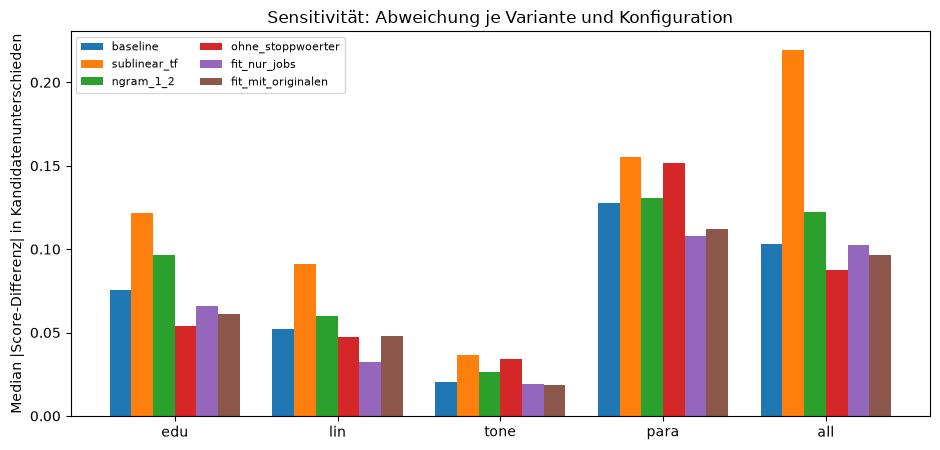

In [23]:
fig, ax = plt.subplots(figsize=(9.5, 4.6))
namen = list(KONFIGS)
breite = 0.8 / len(namen)
for k, n in enumerate(namen):
    ax.bar(np.arange(len(ORDNUNG)) + (k - (len(namen) - 1) / 2) * breite, med_abs[n].to_numpy(), breite, label=n)
ax.set_xticks(range(len(ORDNUNG)))
ax.set_xticklabels(ORDNUNG)
ax.set_ylabel("Median |Score-Differenz| in Kandidatenunterschieden")
ax.set_title("Sensitivität: Abweichung je Variante und Konfiguration")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## Lesehilfe
- **Abschnitt 3:** Zeigt das Prinzip: Bekannte Wörter verdünnen, unbekannte werden ignoriert.
- **Abschnitt 5:** Entscheidet, ob `edu` und `lin` überhaupt wirken können. Kommt fast nichts Bekanntes hinzu, bleibt der Effekt klein.
- **Abschnitt 6:** Prüft, ob die Stoppwortliste Bewertungswörter von `tone` entfernt.
- **Abschnitt 8:** Bleibt die Reihenfolge der Varianten in allen Konfigurationen gleich, sind die Aussagen robust gegenüber der Einstellung. Wechselt sie, muss das im Bericht als Einschränkung stehen.
- Dieses Notebook verändert die Hauptkonfiguration nicht. Eine Änderung nach dem Blick auf Ergebnisse wäre eine nachträgliche Auswahl und müsste als solche begründet und dokumentiert werden.